In [1]:
try:
    import ydf
except:
    !uv pip install -q ydf
    import ydf

print(f"ydf version: {ydf.__version__}")

ydf version: 0.15.0


In [2]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        # ipython = get_ipython()
        # # ipython.run_line_magic("load_ext", "cuml.accel")
        # ipython.run_line_magic("load_ext", "cudf.pandas")
        # print("🚀 GPU detected. RAPIDS accelerators successfully loaded!")
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        print("ℹ️ No GPU detected. Running on standard CPU mode.")
        return f"CORES: {os.cpu_count()}"

get_system_info()

ℹ️ No GPU detected. Running on standard CPU mode.


'CORES: 4'

In [3]:
# %load_ext cuml.accel
# %load_ext cudf.pandas

In [4]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [5]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

In [6]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import TargetEncoder as skTE
from sklearn.model_selection import KFold, train_test_split

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [7]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [8]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"data.csv")

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

print(f"Frame type: {type(train)}\n")

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Frame type: <class 'pandas.core.frame.DataFrame'>

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [9]:
train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [10]:
# import pandas as pd
# from pandas.util import hash_pandas_object

# # Generate hashes
# hash1 = hash_pandas_object(train[base_cols], index=False)
# hash2 = hash_pandas_object(orig[base_cols], index=False)

# # Find rows in orig that are NOT present in train
# new_or_changed_rows = hash2.isin(hash1)

# # Get the actual data for those mismatched rows
# mismatched_orig_data = orig[new_or_changed_rows]
# display(mismatched_orig_data)

In [11]:
# train.head()

In [12]:
# train.describe().T

In [13]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

satisfaction                            2
Type of Travel                          2
Customer Type                           2
Gender                                  2
Class                                   3
Baggage handling                        5
Gate location                           6
Departure/Arrival time convenient       6
Leg room service                        6
Checkin service                         6
On-board service                        6
Inflight wifi service                   6
Food and drink                          6
Online boarding                         6
Seat comfort                            6
Ease of Online booking                  6
Inflight entertainment                  6
Cleanliness                             6
Age                                    75
Departure Delay in Minutes            167
Arrival Delay in Minutes              168
Flight Distance                      3474
dtype: int64

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [15]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


## FEATURE ENGINEERING

In [16]:
## -- DIGITS EXTRACTION --

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

combined = pd.concat([train, test, orig])

digit_cols = []
cols_select = ["Flight Distance"] #, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

for col in cols_select:
    scaled = (combined[col].fillna(0) * (10**4)).astype('int64')
    for k in range(-4, 4): # range(-4, 4)
        dig_col = f"{col}_dig_{k}"
        combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int32').astype('category')
        # combined[dig_col] = (combined[col].fillna(0) // (10**k) % 10).astype('int32').astype('category')
        digit_cols.append(dig_col)

train = combined.iloc[:train_len]
test = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig = combined.iloc[-len(orig):]

# Check nunique, and find which ones are < 2
unique_counts = train[digit_cols].nunique()
drop_cols = unique_counts[unique_counts < 2].index.tolist()

# update digit cols for keep
digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# drop constant features
train = train.drop(columns=drop_cols)
test  = test.drop(columns=drop_cols)
orig  = orig.drop(columns=drop_cols)

del combined
print(f"Total digit features: {len(digit_cols)}\n")

train[digit_cols].nunique()

Total digit features: 4



Flight Distance_dig_2    10
Flight Distance_dig_1    10
Flight Distance_dig_0    10
Flight Distance_dig_3     5
dtype: int64

In [17]:
# ## -- Cyclic encoding --

# for df in [train, test]:
#     for p in [8, 12, 24]:
#         df[f"sleep_hours_sin_{p}"] = np.sin(2 * np.pi * df["sleep_hours"] / p).astype("float32")
#         df[f"sleep_hours_cos_{p}"] = np.cos(2 * np.pi * df["sleep_hours"] / p).astype("float32")

In [18]:
## -- NUMERIC TO CATEGORY for TargetEncoding -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------

# -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = ["Flight Distance"] # "Arrival Delay in Minutes", "Departure Delay in Minutes"]
for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_cat_"
    combined[new_cat] = (pd.factorize(combined[c])[0]).astype('int32')
    # combined[n] = combined[n].astype('category')
    nums_to_cats.append(new_cat)

FEATURES = list(set(FEATURES + nums_to_cats))

## ------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", len(FEATURES))

Features before operation: 25


nums_to_cats:   0%|          | 0/1 [00:00<?, ?it/s]

Features after operation: 26


In [19]:
## -- Frequency encoding -- ⚠️
freq_cols = []

combined = pd.concat([train, test], ignore_index=True)

select_freq = ["Flight Distance"]
#, "Age", "Arrival Delay in Minutes", "Departure Delay in Minutes"]

print("\nCreating frequencies (Safe Global Mapping)...")
for col in select_freq:
    n = f"_freq_{col}"
    print(f"⧗ {n}", end="")

    # Calculate frequencies using ONLY train
    freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

    # Map the training-derived frequencies across all datasets safely
    train[n] = train[col].map(freq_map).fillna(0).astype("float32")
    test[n] = test[col].map(freq_map).fillna(0).astype("float32")
    orig[n] = orig[col].map(freq_map).fillna(0).astype("float32")

    freq_cols.append(n)
    print()

# num_cols = list(set(num_cols + freq_cols))
FEATURES = list(set(FEATURES + freq_cols))

print(f"\n *** Total frequency features: {len(freq_cols)}")


Creating frequencies (Safe Global Mapping)...
⧗ _freq_Flight Distance

 *** Total frequency features: 1


In [20]:
## -- Factorize cat_cols -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Total features before operation:", len(FEATURES))

combined = pd.concat([train, test, orig])
## ------------------------------------------------------------------------
for c in tqdm(cat_cols, desc="factorize_cats"):
    combined[c] = (pd.factorize(combined[c])[0]).astype('int32')

## ------------------------------------------------------------------------
GROUP_COLS = []
grouper  = 'Flight Distance'
agg_cols = ['Class', 'Type of Travel'] + service_cols

for col in agg_cols:
    g_col = f"{col}_{grouper.split(' ')[0]}_GROUPBY".replace(" ", "")
    combined[f"{g_col}_mean"] = combined.groupby([grouper])[col].transform('mean')
    # combined[f"{g_col}_std"] = combined.groupby([grouper])[col].transform('std')
    # combined[f"{g_col}_skew"] = combined.groupby(['Flight Distance'])[col].transform('skew')
    GROUP_COLS.append(g_col)

# for col in service_cols + ['Class', 'Type of Travel']:
#     g_col = f"{col}_AGE_GROUPBY".replace(" ", "")
#     combined[f"{g_col}_mean"] = combined.groupby(['Age'])[col].transform('mean')
    # combined[f"{g_col}_std"] = combined.groupby(['Age'])[col].transform('std')
    # combined[f"{g_col}_skew"] = combined.groupby(['Flight Distance'])[col].transform('skew')
    # groupers.append(g_col)

# FEATURES = list(set(FEATURES + GROUP_COLS))
## ------------------------------------------------------------------------

for c in tqdm(cat_cols, desc="categorize_cats"):
    combined[c] = combined[c].astype("category")

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
orig  = combined.iloc[train_len+test_len:]

del combined
print("Total features after operation:", len(FEATURES))

Total features before operation: 27


factorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

categorize_cats:   0%|          | 0/4 [00:00<?, ?it/s]

Total features after operation: 27


In [21]:
# ## FLOOR/BIN FEATURES -- ⚠️
# floor_cols = []

# combined = pd.concat([train, test, orig])

# for f in tqdm([1000], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Flight Distance']:
#         f_name = f"{c}_flr{f}"
#         print(f" ⧗ {f_name}", end='... ')
#         combined[f_name] = (combined[c].fillna(0) // f).astype('int32')
#         # combined[f_name] = (combined[c].fillna(0) // f).astype('int32').astype('category')
#         floor_cols.append(f_name)
#         print()

# # for f in tqdm([10], desc='Floor features (bins)'):
# #     # print(f, end='-> ')
# #     for c in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
# #         f_name = f"{c}_//_{f}"
# #         print(f" ⧗ {f_name}", end='... ')
# #         combined[f_name] = (combined[c] // f).astype('int32')
# #         floor_cols.append(f_name)
# #         print()

# for f in tqdm([5], desc='Floor features (bins)'):
#     # print(f, end='-> ')
#     for c in ['Age']:
#         age_n = f"{c}_flr{f}"
#         print(f" ⧗ {age_n}", end='... ')
#         combined[age_n] = (combined[c] // f).astype('int32')
#         floor_cols.append(age_n)
#         print()

# combined[f"age{f}_X_dist1000"] = combined[age_n] * combined[f_name]

# # FEATURES = list(set(FEATURES + floor_cols))

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print(f"\n*** Total floor features: {len(floor_cols)}")

# print(train[floor_cols].nunique(dropna=False))

In [22]:
## -- INTERACTIONS -- ⚠️

INTER = []

combo_select = [c for c in base_cols if train[c].nunique() < 10] + ['Flight Distance_//_250', 'Age_//_10']
comb = [c for c in num_cols if (train[c].nunique() < 10) and (c in base_cols)]

combined = pd.concat([train, test, orig], ignore_index=True)
# ------------------------------------------------------------------------
combo_2_1 = list(itertools.combinations(cat_cols, 2))
for c1, c2 in tqdm(combo_2_1, desc='Pairwise Sync Encoding'):
    n_col = f"Bi_{c1}_X_{c2}".replace(" ", "")
    combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
    combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
    # combined[n_col] = combined[n_col].astype('category')
    INTER.append(n_col)

combo_3_1 = list(itertools.combinations(cat_cols, 3)) # + [age_n]
for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
    n_col = f"Tri_{c1}_X_{c2}_X_{c3}".replace(" ", "")
    combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str)
    combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
    # combined[n_col] = combined[n_col].astype('category')
    INTER.append(n_col)

# combo_4_1 = list(itertools.combinations(cat_cols, 4))
# for c1, c2, c3, c4 in tqdm(combo_4_1, desc='Quadwise Sync Encoding'):
#     n_col = f"Quad_{c1}_X_{c2}_X_{c3}_X_{c4}".replace(" ", "")
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str) + '_' + combined[c3].astype(str) + '_' + combined[c4].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)

# combo_1_to_many = list(itertools.product(cat_cols, [age_n]))
# for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
#     n_col = f"Bi2_{c1}_X_{c2}".strip()
#     combo_string = combined[c1].astype(str) + '_' + combined[c2].astype(str)
#     combined[n_col] = pd.factorize(combo_string)[0].astype('int32')
#     # combined[n_col] = combined[n_col].astype('category')
#     INTER.append(n_col)
# ------------------------------------------------------------------------

for n_col in INTER:
    train[n_col] = combined[n_col].iloc[:train_len].values
    test[n_col]  = combined[n_col].iloc[train_len:train_len + test_len].values
    orig[n_col]  = combined[n_col].iloc[train_len + test_len:].values

print(f"Total Interaction Features: {INTER}")

del combined
# train[INTER].head()

Pairwise Sync Encoding:   0%|          | 0/6 [00:00<?, ?it/s]

Triplewise Sync Encoding:   0%|          | 0/4 [00:00<?, ?it/s]

Total Interaction Features: ['Bi_Gender_X_CustomerType', 'Bi_Gender_X_TypeofTravel', 'Bi_Gender_X_Class', 'Bi_CustomerType_X_TypeofTravel', 'Bi_CustomerType_X_Class', 'Bi_TypeofTravel_X_Class', 'Tri_Gender_X_CustomerType_X_TypeofTravel', 'Tri_Gender_X_CustomerType_X_Class', 'Tri_Gender_X_TypeofTravel_X_Class', 'Tri_CustomerType_X_TypeofTravel_X_Class']


In [23]:
# # ==========================================
# # 2. HIGH-IMPACT DOMAIN INTERACTIONS (AUC BOOST) ⚠️
# # ==========================================

# combined = pd.concat([train, test, orig])

# service_cols = [
#     'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
#     'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
#     'Inflight entertainment', 'On-board service', 'Leg room service',
#     'Baggage handling', 'Checkin service', 'Cleanliness'
# ]

# # A. Total Delay & Delay Discrepancy
# # Tree models easily split on raw values, but explicit sums and differences reduce required tree depth
# # combined['Total_Delay'] = combined['Departure Delay in Minutes'].fillna(0) + combined['Arrival Delay in Minutes'].fillna(0)
# # combined['Is_Delayed'] = (combined['Total_Delay'] >= 10).astype('int8').astype('category')
# # combined['Delay_Recovered'] = combined['Departure Delay in Minutes'].fillna(0) - combined['Arrival Delay in Minutes'].fillna(0)

# # B. Aggregated Service Experience Scores (Crucial for Passenger Satisfaction datasets)
# # Capturing the holistic experience mathematically
# combined['Total_Service_Score'] = combined[service_cols].sum(axis=1)
# combined['Mean_Service_Score']  = combined[service_cols].mean(axis=1)
# combined['Variance_Service_Score'] = combined[service_cols].var(axis=1).astype('float32')

# # Segmenting critical service groups
# booking_flow = ['Inflight wifi service', 'Ease of Online booking', 'Online boarding']
# comfort_flow = ['Seat comfort', 'Food and drink', 'Leg room service', 'Cleanliness']
# combined['Digital_Experience_Score'] = combined[booking_flow].mean(axis=1)
# combined['Physical_Comfort_Score'] = combined[comfort_flow].mean(axis=1)

# # # Count of zero-scores (often represents "Not Applicable" or an extreme pain point)
# # combined['Count_Zero_Services'] = (combined[service_cols] == 0).sum(axis=1).astype('int8')
# # combined['Count_High_Services'] = (combined[service_cols] >= 4).sum(axis=1).astype('int8')

# # # C. Distance vs. Age Groupings
# # combined['Distance_per_Year_of_Age'] = combined['Flight Distance'] / (combined['Age'] + 1)

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

# del combined
# print("Arithmetric features ready")

In [24]:
# ## -- base_margin >>> LOAD OTHER MODEL PREDICTIONS --

# link = "/kaggle/input/notebooks/sylvesterdalmeida/ps6e10-tabpfn-se-airline/"
# trn_base_margin = np.load(link+"oof_TABPFNe2loc_959837.npy")
# tst_base_margin = np.load(link+"test_TABPFNe2loc_959837.npy")

# # eps = 1e-15
# # for df in [train, test]:
# #     pos_probs = np.clip(df[base_margin].values, eps, 1 - eps)
# #     logits = np.log(pos_probs / (1 - pos_probs))
# #     # df[f"{base_margin}_logits"] = logits
# #     df[base_margin] = logits

# trn_base_margin.shape, tst_base_margin.shape

In [25]:
## -- extra_feature >>> LOAD ORIGINAL OUTPUTS --
orig_feature = f"ORIG_{TARGET}_preds"

link = "/kaggle/input/notebooks/sylvesterdalmeida/ps6e10-autogluon-original-airline/"
train[orig_feature] = np.load(link+"AG_preds/ag_best_satisfaction_trn.npy")
test[orig_feature]  = np.load(link+"AG_preds/ag_best_satisfaction_tst.npy")

# EPS = 1e-15
# for df in [train, test]:
#     pos_probs = np.clip(df[orig_feature].values, EPS, 1 - EPS)
#     logits = np.log(pos_probs / (1 - pos_probs))
#     # df[orig_feature] = logits
#     df[f"{orig_feature}_logits"] = logits

train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction,Flight Distance_dig_0,Flight Distance_dig_1,Flight Distance_dig_2,Flight Distance_dig_3,Flight Distance_cat_,_freq_Flight Distance,Class_Flight_GROUPBY_mean,TypeofTravel_Flight_GROUPBY_mean,Inflightwifiservice_Flight_GROUPBY_mean,Departure/Arrivaltimeconvenient_Flight_GROUPBY_mean,EaseofOnlinebooking_Flight_GROUPBY_mean,Gatelocation_Flight_GROUPBY_mean,Foodanddrink_Flight_GROUPBY_mean,Onlineboarding_Flight_GROUPBY_mean,Seatcomfort_Flight_GROUPBY_mean,Inflightentertainment_Flight_GROUPBY_mean,On-boardservice_Flight_GROUPBY_mean,Legroomservice_Flight_GROUPBY_mean,Baggagehandling_Flight_GROUPBY_mean,Checkinservice_Flight_GROUPBY_mean,Cleanliness_Flight_GROUPBY_mean,Bi_Gender_X_CustomerType,Bi_Gender_X_TypeofTravel,Bi_Gender_X_Class,Bi_CustomerType_X_TypeofTravel,Bi_CustomerType_X_Class,Bi_TypeofTravel_X_Class,Tri_Gender_X_CustomerType_X_TypeofTravel,Tri_Gender_X_CustomerType_X_Class,Tri_Gender_X_TypeofTravel_X_Class,Tri_CustomerType_X_TypeofTravel_X_Class,ORIG_satisfaction_preds
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,0,0,0,0,0.0,4,9,6,0,0,506.0,0.271978,0.491758,2.821429,3.704670,2.649725,2.951923,3.440934,3.142857,3.505495,3.458791,3.565934,3.166209,3.831044,3.563187,3.510989,0,0,0,0,0,0,0,0,0,0,0.263970
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,1,0,1,1,1.0,1,5,6,0,1,2893.0,0.451172,0.606192,2.735716,2.770772,2.787389,3.085591,3.052811,3.054405,3.223310,3.147507,3.153654,3.228318,3.540633,3.078306,3.099476,1,1,1,1,1,1,1,1,1,1,0.999079
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,0,0,0,0,0.0,1,7,3,1,2,381.0,0.451827,0.591362,2.865449,3.637874,2.850498,2.973422,3.267442,3.335548,3.588040,3.360465,3.674419,3.456811,3.845515,3.737542,3.440199,0,0,0,0,0,0,0,0,0,0,0.000210
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,1,0,0,0,0.0,6,1,6,1,3,664.0,0.737403,0.720930,2.737403,3.344961,2.868217,2.957364,3.414729,3.484496,3.777132,3.698643,3.795543,3.724806,3.968992,3.644380,3.586240,1,2,2,0,0,0,2,2,2,0,0.000148
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,0,1,1,0,0.0,1,8,4,0,4,509.0,0.436526,0.632517,2.768374,2.918708,2.824053,3.189310,3.241648,3.074610,3.358575,3.335189,3.109131,3.236080,3.467706,2.889755,3.250557,2,3,0,2,2,2,3,3,3,2,0.012686


In [26]:
train.nunique()[-20:]

Foodanddrink_Flight_GROUPBY_mean               2391
Onlineboarding_Flight_GROUPBY_mean             2516
Seatcomfort_Flight_GROUPBY_mean                2426
Inflightentertainment_Flight_GROUPBY_mean      2482
On-boardservice_Flight_GROUPBY_mean            2502
Legroomservice_Flight_GROUPBY_mean             2469
Baggagehandling_Flight_GROUPBY_mean            2448
Checkinservice_Flight_GROUPBY_mean             2442
Cleanliness_Flight_GROUPBY_mean                2461
Bi_Gender_X_CustomerType                          4
Bi_Gender_X_TypeofTravel                          4
Bi_Gender_X_Class                                 6
Bi_CustomerType_X_TypeofTravel                    4
Bi_CustomerType_X_Class                           6
Bi_TypeofTravel_X_Class                           6
Tri_Gender_X_CustomerType_X_TypeofTravel          8
Tri_Gender_X_CustomerType_X_Class                12
Tri_Gender_X_TypeofTravel_X_Class                12
Tri_CustomerType_X_TypeofTravel_X_Class          12
ORIG_satisfa

# ML TRAINING

In [27]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=300_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

_ = [c for c in train_X.columns if c not in [ID, TARGET]]
FEATURES = list(set(_))

print(f"Train shape {train_X.shape}")
# train_X.head()

(699635, 54) <class 'pandas.core.frame.DataFrame'>
Train shape (699635, 54)


In [28]:
## -- Handle optional original table aggregations
USE_ORIGINAL = True

import_cols = base_cols # ['Flight Distance'] + cat_cols + service_cols

if USE_ORIGINAL: # try 'std' again later ⚠️
    aggs_ = ["mean", "count"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int32")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int32")

print(X.shape, type(X))
X.head()

original_augmenting:   0%|          | 0/21 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/21 [00:00<?, ?it/s]

(699635, 95) <class 'pandas.core.frame.DataFrame'>


,Flight Distance_dig_2,Inflightwifiservice_Flight_GROUPBY_mean,Type of Travel,Baggage handling,Bi_TypeofTravel_X_Class,Departure/Arrival time convenient,Tri_Gender_X_TypeofTravel_X_Class,ORIG_satisfaction_preds,Leg room service,Flight Distance_cat_,Flight Distance_dig_1,On-boardservice_Flight_GROUPBY_mean,Checkinservice_Flight_GROUPBY_mean,TypeofTravel_Flight_GROUPBY_mean,Inflight wifi service,Tri_Gender_X_CustomerType_X_Class,Customer Type,On-board service,Departure Delay in Minutes,Bi_Gender_X_TypeofTravel,Arrival Delay in Minutes,Tri_CustomerType_X_TypeofTravel_X_Class,Gender,Seat comfort,Seatcomfort_Flight_GROUPBY_mean,Age,Class_Flight_GROUPBY_mean,Departure/Arrivaltimeconvenient_Flight_GROUPBY_mean,Legroomservice_Flight_GROUPBY_mean,Class,Food and drink,Bi_CustomerType_X_Class,Cleanliness,Gatelocation_Flight_GROUPBY_mean,Foodanddrink_Flight_GROUPBY_mean,Cleanliness_Flight_GROUPBY_mean,Bi_CustomerType_X_TypeofTravel,Tri_Gender_X_CustomerType_X_TypeofTravel,Bi_Gender_X_CustomerType,Ease of Online booking,_freq_Flight Distance,EaseofOnlinebooking_Flight_GROUPBY_mean,Gate location,Flight Distance_dig_3,Flight Distance,Online boarding,Onlineboarding_Flight_GROUPBY_mean,Inflightentertainment_Flight_GROUPBY_mean,Checkin service,Inflight entertainment,Baggagehandling_Flight_GROUPBY_mean,Flight Distance_dig_0,Bi_Gender_X_Class,oTE_Age_mean,oTE_Age_count,oTE_Flight Distance_mean,oTE_Flight Distance_count,oTE_Inflight wifi service_mean,oTE_Inflight wifi service_count,oTE_Departure/Arrival time convenient_mean,oTE_Departure/Arrival time convenient_count,oTE_Ease of Online booking_mean,oTE_Ease of Online booking_count,oTE_Gate location_mean,oTE_Gate location_count,oTE_Food and drink_mean,oTE_Food and drink_count,oTE_Online boarding_mean,oTE_Online boarding_count,oTE_Seat comfort_mean,oTE_Seat comfort_count,oTE_Inflight entertainment_mean,oTE_Inflight entertainment_count,oTE_On-board service_mean,oTE_On-board service_count,oTE_Leg room service_mean,oTE_Leg room service_count,oTE_Baggage handling_mean,oTE_Baggage handling_count,oTE_Checkin service_mean,oTE_Checkin service_count,oTE_Cleanliness_mean,oTE_Cleanliness_count,oTE_Departure Delay in Minutes_mean,oTE_Departure Delay in Minutes_count,oTE_Arrival Delay in Minutes_mean,oTE_Arrival Delay in Minutes_count,oTE_Gender_mean,oTE_Gender_count,oTE_Customer Type_mean,oTE_Customer Type_count,oTE_Type of Travel_mean,oTE_Type of Travel_count,oTE_Class_mean,oTE_Class_count
0,6,2.821429,0,4,0,4,0,0.263970,4,0,9,3.565934,3.563187,0.491758,4,0,0,3,0,0,0.0,0,0,1,3.505495,36,0.271978,3.704670,3.166209,0,1,0,1,2.951923,3.440934,3.510989,0,0,0,4,506.0,2.649725,3,0,694,4,3.142857,3.458791,3,1,3.831044,4,0,0.354726,2867.0,0.351852,54.0,0.600767,24775.0,0.388614,31880.0,0.531623,24444.0,0.347062,35717.0,0.199551,16051.0,0.623011,38468.0,0.223325,15108.0,0.141946,15675.0,0.318093,28542.0,0.583096,35886.0,0.480636,46761.0,0.450794,35453.0,0.196963,16729.0,0.459390,73356.0,0.47407,72753.0,0.428975,65899.0,0.478115,106100.0,0.101326,40187.0,0.187673,58309.0
1,6,2.735716,1,5,1,5,1,0.999079,5,1,5,3.153654,3.078306,0.606192,5,1,0,5,0,1,0.0,1,1,4,3.223310,56,0.451172,2.770772,3.228318,1,5,1,3,3.085591,3.052811,3.099476,1,1,1,5,2893.0,2.787389,5,0,651,4,3.054405,3.147507,4,5,3.540633,1,1,0.572727,2310.0,0.331915,235.0,0.990178,14356.0,0.424709,27998.0,0.734676,17424.0,0.568040,17409.0,0.550882,27957.0,0.623011,38468.0,0.560293,39756.0,0.650615,31544.0,0.646379,29492.0,0.614561,30905.0,0.615916,33878.0,0.460023,36333.0,0.433075,30639.0,0.459390,73356.0,0.47407,72753.0,0.440115,63981.0,0.478115,106100.0,0.583724,89693.0,0.694434,62160.0
2,3,2.865449,0,4,0,4,0,0.000210,3,2,7,3.674419,3.737542,0.591362,3,0,0,4,0,0,0.0,0,0,3,3.588040,31,0.451827,3.637874,3.456811,0,3,0,3,2.973422,3.267442,3.440199,0,0,0,2,381.0,2.850498,5,1,1371,3,3.335548,3.360465,5,3,3.845515,1,0,0.439960,2007.0,0.428571,63.0,0.251825,32185.0,0.388614,31880.0,0.303484,30051.0,0.568040,17409.0,0.397424,27794.0,0.137626,27117.0,0.214078,23328.0,0.273

In [29]:
# ## -- Reduce data memory --

# def reduce_memory(df):
#     # Use copy() if you want to avoid modifying the original dataframe in place
#     # df = df.copy()

#     old_size = df.memory_usage(deep=True).sum() / (1024 * 1024)

#     for c in tqdm(df.columns, desc='Reducing memory...'):
#         col_type = df[c].dtype

#         # Check if type is numeric (integers and floats)
#         if np.issubdtype(col_type, np.integer):
#             df[c] = pd.to_numeric(df[c], downcast='integer')
#         elif np.issubdtype(col_type, np.floating):
#             df[c] = pd.to_numeric(df[c], downcast='float')
#         # Optional: Convert object types with low cardinality to category
#         elif col_type == object or col_type.name == 'category':
#             if df[c].nunique() < len(df[c]) * 0.5:  # If less than 50% unique values
#                 df[c] = df[c].astype('category')

#     new_size = df.memory_usage(deep=True).sum() / (1024 * 1024)
#     print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f} MB\n")

#     return df

# X = reduce_memory(X)
# X_test = reduce_memory(X_test)
# # orig = reduce_memory(orig)

# print(f"Data memory reduced!")
# gc.collect()

In [30]:
# X.info()

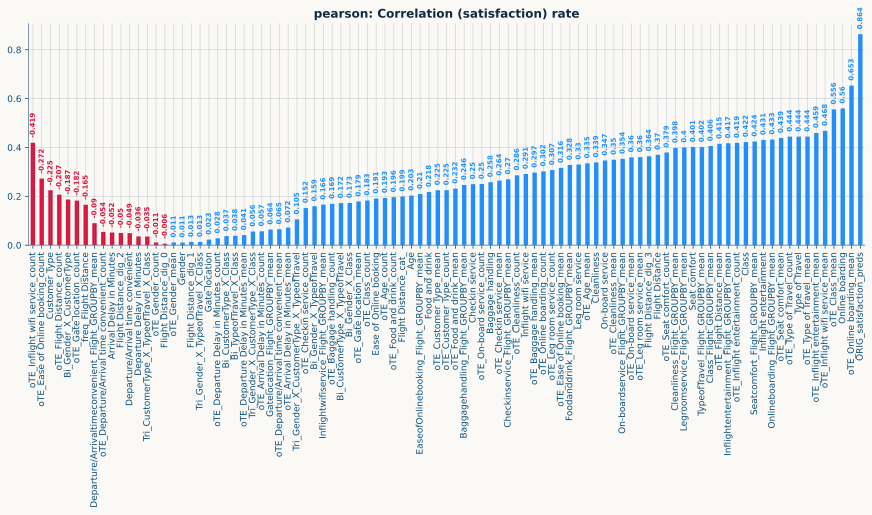

In [31]:
corr_type = ['pearson', 'spearman'][0]

plt.figure(figsize=(15, 4))
corr_df = X.corrwith(train_X[TARGET], method=corr_type).sort_values()
corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
for i, v in enumerate(corr_df.values):
    plt.text(
        i, np.abs(v) + 0.02, np.round(v, 3),
        size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
        va='bottom', ha='center', rotation=90,
    )

plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
plt.show()

In [45]:
# -- Set up parameters --

local_params = {
    'task': ydf.Task.CLASSIFICATION,
    'growing_strategy': "LOCAL",
    'max_depth': 8,
}

global_params = {
    'task': ydf.Task.CLASSIFICATION,
    'growing_strategy': "BEST_FIRST_GLOBAL",
    'max_num_nodes': None,
}

all_models = {
    'loc': ('YDFloc_se', local_params),
    'glo': ('YDFglo_se', global_params),
}

print("🤖 Model parameters defined!")

all_models
# all_models['gbdt']

🤖 Model parameters defined!


{'loc': ('YDFloc_se',
  {'task': <Task.CLASSIFICATION: 'CLASSIFICATION'>,
   'growing_strategy': 'LOCAL',
   'max_depth': 8}),
 'glo': ('YDFglo_se',
  {'task': <Task.CLASSIFICATION: 'CLASSIFICATION'>,
   'growing_strategy': 'BEST_FIRST_GLOBAL',
   'max_num_nodes': None})}

In [46]:
try:
    import optuna
except ModuleNotFoundError:
    !pip install optuna -q
    import optuna

def objective(trial):

    FOLDS = 5
    skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

    _id = 'gbt' # 'gbt' 'los' 'gra'
    model_name = all_models[_id][0]
    params = all_models[_id][1].copy()
    params.update({
        # 'sampling_method': "gradient_based",
        'max_depth': trial.suggest_int('max_depth', 4, 10),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0, step=0.001),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0, step=0.001),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 3.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 5.0, log=True),
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
        'early_stopping_rounds': 100,
        'random_state': 42,
        'learning_rate': 0.01,
    })

    fold_scores = []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
        X_tr = X.iloc[tr_idx].copy()
        X_val = X.iloc[val_idx].copy()
        y_tr = y.iloc[tr_idx]
        y_val = y.iloc[val_idx]
        X_tst = X_test.copy()

        # Target encoding
        if CFG.TE:
            te_cols = nums_to_cats + INTER # + floor_cols
            smooth = 'auto'
            # print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
            TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
            tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
            va_enc = TE.transform(X_val[te_cols])
            ts_enc = TE.transform(X_tst[te_cols])

            te_names = [f"TE{smooth}_{col}" for col in te_cols]
            X_tr[te_names]  = tr_enc
            X_val[te_names] = va_enc
            X_tst[te_names] = ts_enc

            combos_to_drop = te_cols

            X_tr  = X_tr.drop(columns=combos_to_drop)
            X_val = X_val.drop(columns=combos_to_drop)
            X_tst = X_tst.drop(columns=combos_to_drop)
        # ------------------------------------------------------------------------------
        if fold == 1: print(f"{model_name} | train={X_tr.shape}, valid={X_val.shape}\n")
        # print("#"*16)
        # print(f"### Fold {fold}/{FOLDS} ...")
        # print("#"*16)

        trn_margin = trn_base_margin[tr_idx] if 'trn_base_margin' in globals() else None
        val_margin = trn_base_margin[val_idx] if 'trn_base_margin' in globals() else None
        tst_margin = tst_base_margin if 'tst_base_margin' in globals() else None

        model = xgb.XGBClassifier(**params)
        model.fit(
            X_tr, y_tr, verbose=False,
            eval_set = [(X_tr, y_tr), (X_val, y_val)],
            base_margin = trn_margin,
            # base_margin_eval_set = [trn_margin, val_margin],
        )

        val_preds = model.predict_proba(X_val, base_margin=val_margin)[:, 1]
        fold_scores.append(roc_auc_score(y_val, val_preds))

        torch.cuda.empty_cache()

    avg_auc = np.round(np.mean(fold_scores), 6)
    std_auc = np.round(np.std(fold_scores), 6)
    print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")

    return avg_auc

print("Optuna search function ready!")

Optuna search function ready!


In [47]:
# # ==========================================
# # RUN THE OPTUNA SEARCH
# # ==========================================
# opt_study = optuna.create_study(direction="maximize")
# opt_study.optimize(objective, n_trials=30, timeout=3600)

# print("\n💥 Optimization Finished!")
# print(f"Best OOF AUC: {opt_study.best_value:.6f}")
# print("Best Params:", opt_study.best_params)

In [48]:
if 'opt_study' in globals():
    print(f"Best OOF AUC: {study.best_value:.6f}")
    print("Best Params:", study.best_params)

In [49]:
## -- Visualize parameter importance
if 'opt_study' in globals():
    optuna.visualization.plot_param_importances(opt_study).show()
    optuna.visualization.plot_slice(opt_study).show()
    optuna.visualization.plot_optimization_history(opt_study).show()

In [50]:
class CFG:
    FOLDS = 5
    SEED  = 42
    TE = True if 'nums_to_cats' in globals() else False
    ES = 50 # 30, 50
    VERB = 1 # 1, 2

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

_id = 'loc' # 'loc' 'glo'
model_name = all_models[_id][0]
print(f"\n🚀 Training {model_name} with {FOLDS } Folds")

oof_preds  = np.zeros(len(train_X))
test_preds = np.zeros(len(X_test))

fold_scores = []
best_iterations = []
feat_importances = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_tr = X.iloc[tr_idx].copy()
    X_val = X.iloc[val_idx].copy()
    y_tr = y.iloc[tr_idx]
    y_val = y.iloc[val_idx]
    X_tst = X_test.copy()

    # Target encoding
    if CFG.TE:
        te_cols = nums_to_cats + INTER # + floor_cols
        # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_tr[te_cols], y_tr)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_tr[te_names]  = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols

        X_tr  = X_tr.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # ------------------------------------------------------------------------------
    if fold == 1: print(f"train={X_tr.shape}, valid={X_val.shape}\n")
    print("#"*16)
    print(f"### Fold {fold}/{FOLDS}")
    print("#"*16)

    params = all_models[_id][1].copy()
    seeder = 42 #+ (fold-1)

    # -- use optuna results
    params.update({
        'num_trees': 1500,
        'shrinkage': 0.05, # def=0.1
        'random_seed': seeder,
        # 'categorical_algorithm': 'RANDOM', # 'CART', 'RANDOM', 'ONE_HOT'
        # 'sampling_method': 'GOSS', # 'RANDOM', 'GOSS', 'SELGB'
        'early_stopping_num_trees_look_ahead': CFG.ES,
        # 'early_stopping_initial_iteration': 10,
        # 'split_axis': , # 'AXIS_ALIGNED', 'SPARSE_OBLIQUE', 'MHLD_OBLIQUE'
        # 'subsample': 0.95, # default RANDOM sampling
        # 'goss_alpha': 0.2, # activates GOSS sampling
        # 'l2_regularization': 1.0,
        # 'early_stopping': 'NONE', # 'NONE', 'MIN_LOSS_FINAL', 'LOSS_INCREASE'
        # 'min_examples': 10,
        # 'num_discretized_numerical_bins': 1024,
    })

    trn_margin = trn_base_margin[tr_idx] if 'trn_base_margin' in globals() else None
    val_margin = trn_base_margin[val_idx] if 'trn_base_margin' in globals() else None
    tst_margin = tst_base_margin.copy() if 'tst_base_margin' in globals() else None

    if fold == 1: display(X_tr.head())

    model = ydf.GradientBoostedTreesLearner(
        **params,
        label=TARGET,
        # feature_selector=ydf.BackwardSelectionFeatureSelector(
        # allow_structural_variable_importance=True
        # ),
        # class_weights=get_class_weights(y_train) if use_weights else None,
        # features=flat_features,   # 1. Semantic for categories goes here
        # include_all_columns=True, # 2. Include all features for training
    ).train(
        ds=pd.concat([X_tr, y_tr], axis=1),
        valid=pd.concat([X_val, y_val], axis=1),
        verbose=CFG.VERB,
    )

    val_preds = model.predict(X_val)
    oof_preds[val_idx] = val_preds

    fold_test_preds = model.predict(X_tst)
    test_preds += fold_test_preds / FOLDS

    fold_score = roc_auc_score(y_val, val_preds)
    fold_scores.append(fold_score)

    best_iter = model.num_trees()
    best_iterations.append(best_iter)

    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} AUC: {fold_score:.6f}{Style.RESET_ALL}", end=" | ")
    print(f"seed={seeder}, tree={best_iter}\n")
    torch.cuda.empty_cache()

model_name = model_name + f"({X_tr.shape[1]})"
features_used = X_tr.columns

## -- CV results --
fold_results = {}

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_tr.shape}")
print(f"{'='*50}")
for i, (s, t) in enumerate(zip(fold_scores, best_iterations), 1):
    print(f" • Fold {i} AUC: {s:.6f} @ tree {t}")
    fold_results[f"fold_{i}"] = s

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
avg_auc = np.round(np.mean(fold_scores), 6)
std_auc = np.round(np.std(fold_scores), 6)

print("-"*50)
print(f"OOF score: {Fore.BLUE}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.BLUE}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0) / 60
print(f"{tt:.2f} mins\n")

del X_tr, y_tr


🚀 Training YDFloc_se with 5 Folds
⚡️ scikit_TE (smooth=auto) | features (11)
train=(559708, 95), valid=(139927, 95)

################
### Fold 1/5
################


,Flight Distance_dig_2,Inflightwifiservice_Flight_GROUPBY_mean,Type of Travel,Baggage handling,Departure/Arrival time convenient,ORIG_satisfaction_preds,Leg room service,Flight Distance_dig_1,On-boardservice_Flight_GROUPBY_mean,Checkinservice_Flight_GROUPBY_mean,TypeofTravel_Flight_GROUPBY_mean,Inflight wifi service,Customer Type,On-board service,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Seat comfort,Seatcomfort_Flight_GROUPBY_mean,Age,Class_Flight_GROUPBY_mean,Departure/Arrivaltimeconvenient_Flight_GROUPBY_mean,Legroomservice_Flight_GROUPBY_mean,Class,Food and drink,Cleanliness,Gatelocation_Flight_GROUPBY_mean,Foodanddrink_Flight_GROUPBY_mean,Cleanliness_Flight_GROUPBY_mean,Ease of Online booking,_freq_Flight Distance,EaseofOnlinebooking_Flight_GROUPBY_mean,Gate location,Flight Distance_dig_3,Flight Distance,Online boarding,Onlineboarding_Flight_GROUPBY_mean,Inflightentertainment_Flight_GROUPBY_mean,Checkin service,Inflight entertainment,Baggagehandling_Flight_GROUPBY_mean,Flight Distance_dig_0,oTE_Age_mean,oTE_Age_count,oTE_Flight Distance_mean,oTE_Flight Distance_count,oTE_Inflight wifi service_mean,oTE_Inflight wifi service_count,oTE_Departure/Arrival time convenient_mean,oTE_Departure/Arrival time convenient_count,oTE_Ease of Online booking_mean,oTE_Ease of Online booking_count,oTE_Gate location_mean,oTE_Gate location_count,oTE_Food and drink_mean,oTE_Food and drink_count,oTE_Online boarding_mean,oTE_Online boarding_count,oTE_Seat comfort_mean,oTE_Seat comfort_count,oTE_Inflight entertainment_mean,oTE_Inflight entertainment_count,oTE_On-board service_mean,oTE_On-board service_count,oTE_Leg room service_mean,oTE_Leg room service_count,oTE_Baggage handling_mean,oTE_Baggage handling_count,oTE_Checkin service_mean,oTE_Checkin service_count,oTE_Cleanliness_mean,oTE_Cleanliness_count,oTE_Departure Delay in Minutes_mean,oTE_Departure Delay in Minutes_count,oTE_Arrival Delay in Minutes_mean,oTE_Arrival Delay in Minutes_count,oTE_Gender_mean,oTE_Gender_count,oTE_Customer Type_mean,oTE_Customer Type_count,oTE_Type of Travel_mean,oTE_Type of Travel_count,oTE_Class_mean,oTE_Class_count,TEauto_Flight Distance_cat_,TEauto_Bi_Gender_X_CustomerType,TEauto_Bi_Gender_X_TypeofTravel,TEauto_Bi_Gender_X_Class,TEauto_Bi_CustomerType_X_TypeofTravel,TEauto_Bi_CustomerType_X_Class,TEauto_Bi_TypeofTravel_X_Class,TEauto_Tri_Gender_X_CustomerType_X_TypeofTravel,TEauto_Tri_Gender_X_CustomerType_X_Class,TEauto_Tri_Gender_X_TypeofTravel_X_Class,TEauto_Tri_CustomerType_X_TypeofTravel_X_Class
0,6,2.821429,0,4,4,0.263970,4,9,3.565934,3.563187,0.491758,4,0,3,0,0.0,0,1,3.505495,36,0.271978,3.704670,3.166209,0,1,1,2.951923,3.440934,3.510989,4,506.0,2.649725,3,0,694,4,3.142857,3.458791,3,1,3.831044,4,0.354726,2867.0,0.351852,54.0,0.600767,24775.0,0.388614,31880.0,0.531623,24444.0,0.347062,35717.0,0.199551,16051.0,0.623011,38468.0,0.223325,15108.0,0.141946,15675.0,0.318093,28542.0,0.583096,35886.0,0.480636,46761.0,0.450794,35453.0,0.196963,16729.0,0.459390,73356.0,0.47407,72753.0,0.428975,65899.0,0.478115,106100.0,0.101326,40187.0,0.187673,58309.0,0.330480,0.497467,0.096517,0.157086,0.097445,0.179404,0.097236,0.096459,0.170536,0.096311,0.097237
1,6,2.735716,1,5,5,0.999079,5,5,3.153654,3.078306,0.606192,5,0,5,0,0.0,1,4,3.223310,56,0.451172,2.770772,3.228318,1,5,3,3.085591,3.052811,3.099476,5,2893.0,2.787389,5,0,651,4,3.054405,3.147507,4,5,3.540633,1,0.572727,2310.0,0.331915,235.0,0.990178,14356.0,0.424709,27998.0,0.734676,17424.0,0.568040,17409.0,0.550882,27957.0,0.623011,38468.0,0.560293,39756.0,0.650615,31544.0,0.646379,29492.0,0.614561,30905.0,0.615916,33878.0,0.460023,36333.0,0.433075,30639.0,0.459390,73356.0,0.47407,72753.0,0.440115,63981.0,0.478115,106100.0,0.583724,89693.0,0.694434,62160.0,0.304013,0.492751,0.599799,0.729343,0.709130,0.781828,0.731635,0.708843,0.784095,0.737039,0.790793
3,6,2.737403,0,3,5,0.000148,5,1,3.795543,3.644380,0.720930,3,0,4,0,0.0,1,3,3.777132,10,0.737403,3.344961,3.724806,0,3,3,2.957364,3.414729,3.586240,3,664.

Train model on 559708 training examples and 139927 validation examples
Model trained in 0:20:56.883754
Fold 1 AUC: 0.960857 | seed=42, tree=332

⚡️ scikit_TE (smooth=auto) | features (11)
################
### Fold 2/5
################
Train model on 559708 training examples and 139927 validation examples
Model trained in 0:16:31.471633
Fold 2 AUC: 0.959780 | seed=42, tree=242

⚡️ scikit_TE (smooth=auto) | features (11)
################
### Fold 3/5
################
Train model on 559708 training examples and 139927 validation examples
Model trained in 0:18:29.250695
Fold 3 AUC: 0.961432 | seed=42, tree=281

⚡️ scikit_TE (smooth=auto) | features (11)
################
### Fold 4/5
################
Train model on 559708 training examples and 139927 validation examples
Model trained in 0:18:29.428282
Fold 4 AUC: 0.960832 | seed=42, tree=269

⚡️ scikit_TE (smooth=auto) | features (11)
################
### Fold 5/5
################
Train model on 559708 training examples and 139927 validatio

In [51]:
# ==================================================
# 5-FOLD CV: YDFglo_se(95) | (559708, 95)
# ==================================================
#  • Fold 1 AUC: 0.960877 @ tree 292
#  • Fold 2 AUC: 0.959735 @ tree 278
#  • Fold 3 AUC: 0.961467 @ tree 243
#  • Fold 4 AUC: 0.960881 @ tree 354
#  • Fold 5 AUC: 0.960768 @ tree 223
# --------------------------------------------------
# OOF score: 0.960734
# AVG score: 0.960746 ± 0.000562
# --------------------------------------------------
# 50.32 mins

# ==================================================
# 5-FOLD CV: YDFloc_se(95) | (559708, 95)
# ==================================================
#  • Fold 1 AUC: 0.960857 @ tree 332
#  • Fold 2 AUC: 0.959780 @ tree 242
#  • Fold 3 AUC: 0.961432 @ tree 281
#  • Fold 4 AUC: 0.960832 @ tree 269
#  • Fold 5 AUC: 0.960790 @ tree 310
# --------------------------------------------------
# OOF score: 0.960733
# AVG score: 0.960738 ± 0.000534
# --------------------------------------------------
# 94.97 mins

In [53]:
# ==================================================
# 5-FOLD CV: YDFloc(21) | (559708, 21)
# ==================================================
#  • Fold 1 AUC: 0.958293 @ tree 299
#  • Fold 2 AUC: 0.957274 @ tree 300
#  • Fold 3 AUC: 0.959008 @ tree 300
#  • Fold 4 AUC: 0.958331 @ tree 299
#  • Fold 5 AUC: 0.958488 @ tree 300
# --------------------------------------------------
# OOF score: 0.958273
# AVG score: 0.958279 ± 0.000564
# --------------------------------------------------
# 11.67 mins

# ==================================================
# 5-FOLD CV: YDFglo_se(21) | (559708, 21)
# ==================================================
#  • Fold 1 AUC: 0.958464 @ tree 300
#  • Fold 2 AUC: 0.957287 @ tree 300
#  • Fold 3 AUC: 0.959338 @ tree 299
#  • Fold 4 AUC: 0.958519 @ tree 295
#  • Fold 5 AUC: 0.958837 @ tree 300
# --------------------------------------------------
# OOF score: 0.95848
# AVG score: 0.958489 ± 0.000676
# --------------------------------------------------
# 11.79 mins

In [54]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

fold_df = pd.DataFrame.from_dict(fold_results, orient='index', columns=['score'])
print(fold_df.to_string())

print("-"*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print("-"*25)

print(f"{tt:.2f} mins")

           score
fold_1  0.960857
fold_2  0.959780
fold_3  0.961432
fold_4  0.960832
fold_5  0.960790
-------------------------
YDFloc_se(95)_960738
-------------------------
94.97 mins


In [55]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit

,id,satisfaction
0,699635,0.220065
1,699636,0.660863
2,699637,0.915331
3,699638,0.073406
4,699639,0.046208
...,...,...
299839,999474,0.031017
299840,999475,0.040763
299841,999476,0.223261
299842,999477,0.023868


In [56]:
# !rm -r /kaggle/working

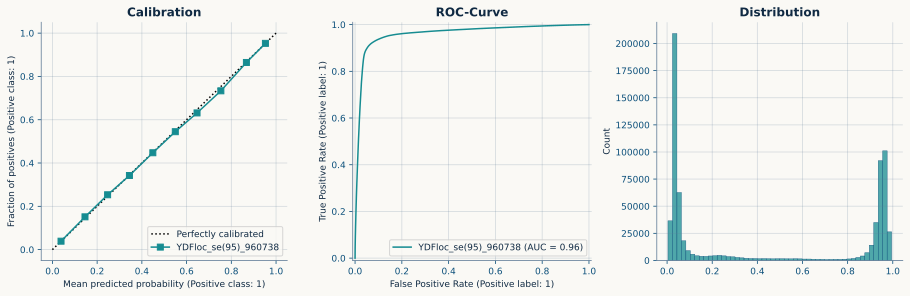

In [57]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12.5, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

# for ax in axs:
#     ax.legend(loc='lower right')

plt.tight_layout(pad=0.2)
plt.show()

In [58]:
# Check final evaluation metrics computed strictly on the validation set
print(model.validation_evaluation())

# Evaluate the model
evaluation = model.evaluate(pd.concat([X_val, y_val], axis=1))
evaluation

accuracy: 0.927069
confusion matrix:
    label (row) \ prediction (col)
    +-------+-------+-------+
    |       |     0 |     1 |
    +-------+-------+-------+
    |     0 | 73485 |  4374 |
    +-------+-------+-------+
    |     1 |  5831 | 56237 |
    +-------+-------+-------+
loss: 0.447027



Label \ Pred,0,1
0,73485,4374
1,5831,56237


In [43]:
# -- YDF Analysis Report --

analysis = model.analyze(
    pd.concat([X_val, y_val], axis=1),
    sampling = 0.2, # d=1.0
    # num_bins = 100, # d=50
    # permutation_variable_importance_rounds = 2, # d=1
)

analysis